# A14 · 预算节奏与反馈控制

先修：公用31–34；A13。

证据类型：**明确构造机制实验（非真实广告日志）**。本章不声称工业系统复现或线上收益。

学习顺序：先预测 → 只改一个变量 → 运行 → 解释结果。

## 问题与输入输出契约

旧24章累计比例门控是硬阈值。这里控制m_t=clip(m_{t-1}+η(target_t-spend_{t-1})/B)，报价=.7m_t；它是比例误差的积分式反馈教学变体，非完整PID或最优控制。无节奏、硬门控、反馈三策略在同样价格序列比较；每请求先检查支付≤剩余预算。匀速花费不等于价值最大化，控制器也不能保证最终花完。

运行前预测：本章只改变的变量会使哪一项结果变化？哪些不变量必须保持？

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'reclab').exists(): root=root.parent
if str(root) not in sys.path: sys.path.insert(0,str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab import ads_curriculum as ac

## 运行单变量对照

输入是源码中可见的小型构造数据，输出单位和约束按上文定义。运行断言核验数学与账本。

,pattern,policy,spend,value
0,burst,none,4.0,20.0
1,burst,gate,3.8,19.0
2,burst,feedback,7.2,24.0
3,sparse,none,3.0,10.0
4,sparse,gate,3.0,10.0
5,sparse,feedback,7.5,9.0
6,drift,none,6.0,20.0
7,drift,gate,3.9,13.0
8,drift,feedback,7.2,16.0


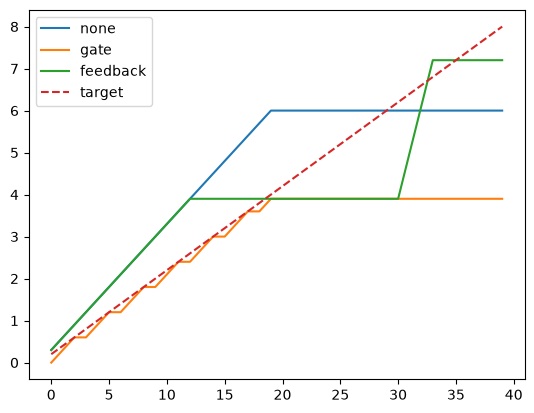

In [2]:
summaries=[]
for pattern in ('burst','sparse','drift'):
 for policy in ('none','gate','feedback'):
  r=ac.pacing(pattern,policy);summaries.append({k:v for k,v in r.items() if k!='trace'})
  if pattern=='drift': plt.plot([x['spend'] for x in r['trace']],label=policy)
display(pd.DataFrame(summaries));plt.plot([x['target'] for x in r['trace']],label='target',linestyle='--');plt.legend();plt.show()
assert all(r['spend']<=8+1e-12 for r in summaries)

## 解释与局限

在稀疏流量中可能欠花，漂移后反馈可提高报价但受限于剩余预算；不要删掉控制器未胜出的情景。当前每次赢标价值相同，若价值随时间变化，追求匀速可能牺牲高价值机会。

## 查看源码，再做练习

只把gain从.8改成2，比较累计误差与振荡；再解释为什么无需为花完预算购买低于成本的价值。

In [3]:
import inspect
print(inspect.getsource(ac.pacing))

def pacing(pattern='burst', policy='feedback', budget=8., gain=.8):
    if pattern not in ('burst','sparse','drift') or policy not in ('none','gate','feedback'): raise ValueError('Invalid scenario')
    prices={'burst':[.2]*20+[.8]*20,'sparse':[1.5]*30+[.3]*10,'drift':[.3]*20+[1.1]*20}[pattern]
    spend=0.; multiplier=1.; trace=[]; value=0.
    for t,price in enumerate(prices):
        target=budget*(t+1)/len(prices)
        if policy=='feedback' and budget>0: multiplier=float(np.clip(multiplier+gain*(target-spend)/budget,.05,3.))
        bid=(.7*multiplier if policy=='feedback' else .7)
        allowed=policy!='gate' or spend+price<=target
        win=allowed and bid>=price and spend+price<=budget+1e-12
        if win: spend+=price;value+=1.
        trace.append(dict(t=t+1,target=target,spend=spend,multiplier=multiplier,won=bool(win)))
        assert -1e-12<=spend<=budget+1e-12
    return dict(pattern=pattern,policy=policy,spend=spend,value=value,trace=trace)



## 来源与下一步

A-RTB 118–131页。这是Lab自行设计的小实验，不复制讲义全文。

[GitHub中文单章](https://github.com/SocratesClub/ccrbook/blob/6dbd5650f2adc6e257e5bd5d156bc50a72560ee9/slides/Chapter%208%20%E8%AE%A1%E7%AE%97%E5%B9%BF%E5%91%8A.pptx) · [作者RTB讲义](https://wnzhang.net/slides/cikm-16-rtb-full.pdf)。中文PPT不是现代广告工程全套课；不将历史平台机制描述当作当前市场事实。

完成练习后回到广告学习路径，继续下一语义单元。